<a href="https://colab.research.google.com/github/gathanraihanalsaleh/SKRIPSI/blob/main/SKRIPSI_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORT DATA**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving DATA_BALITA.zip to DATA_BALITA.zip


In [ ]:
import zipfile
import os

zip_file_name = 'DATA_BALITA.zip'
extract_dir = 'DATA_BALITA'

if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Ekstraksi selesai ✅")

Ekstraksi selesai ✅


In [ ]:
import pandas as pd

#VALIDASI FILE

valid_ext = ['.jpg', '.jpeg', '.png']

image_files = []
non_image_files = []

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        full_path = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower()

        if ext in valid_ext:
            image_files.append(full_path)
        else:
            non_image_files.append(full_path)


#HASIL VALIDASI

print("\n📊 HASIL VALIDASI DATASET")
print(f"Total citra       : {len(image_files)}")
print(f"File non-citra    : {len(non_image_files)}")


#TAMPILKAN FILE NON-CITRA

if len(non_image_files) > 0:
    print("\n⚠️ File non-citra ditemukan:")
    for f in non_image_files:
        print("-", f)


#CEK FILE EXCEL (OPSIONAL)

for f in non_image_files:
    if f.endswith('.xlsx'):
        print("\n📄 Preview isi Excel:")
        df = pd.read_excel(f)
        print(df.head())


#VALIDASI FINAL

if len(image_files) == 120:
    print("\n✅ Dataset VALID (120 citra siap digunakan)")
else:
    print("\n⚠️ Jumlah citra tidak sesuai!")

if len(non_image_files) == 1:
    print("ℹ️ Terdapat 1 file tambahan (Excel) → Aman")


📊 HASIL VALIDASI DATASET
Total citra       : 120
File non-citra    : 1

⚠️ File non-citra ditemukan:
- DATA_BALITA/DATA_BALITA/DATASET_FINAL.xlsx

📄 Preview isi Excel:
   No    Nama Balita  BB (kg)  TB (cm)  LILA (cm)  LIKA (cm)      Umur  \
0   1     Adhe Fitri      5.8     65.0       15.8       40.4  24 Bulan   
1   2   Andi Hariati      5.5     59.0        NaN       47.3  24 Bulan   
2   3     Anwar Amir      6.7     71.5       14.4        NaN  28 Bulan   
3   4          Asmar      8.1     72.5        NaN       39.7  30 Bulan   
4   5  Eka Andriyani      6.9     73.0       17.1       40.8  28 Bulan   

   Kategori Jenis Kelamin  
0  Stunting             P  
1  Stunting             P  
2  Stunting             L  
3  Stunting             L  
4  Stunting             P  

✅ Dataset VALID (120 citra siap digunakan)
ℹ️ Terdapat 1 file tambahan (Excel) → Aman


# **PREPROCESSING DATA**

PREPROCESSING NUMERIK

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler # Import MinMaxScaler for normalization

excel_path = '/content/DATA_BALITA/DATA_BALITA/DATASET_FINAL.xlsx'
df = pd.read_excel(excel_path)

# Convert 'Umur' column to numeric (months)
df['Umur'] = df['Umur'].astype(str).str.replace(' Bulan', '', regex=False).astype(int)

print("✅ Data berhasil dimuat")
print(df.head())

✅ Data berhasil dimuat
   No    Nama Balita  BB (kg)  TB (cm)  LILA (cm)  LIKA (cm)  Umur  Kategori  \
0   1     Adhe Fitri      5.8     65.0       15.8       40.4    24  Stunting   
1   2   Andi Hariati      5.5     59.0        NaN       47.3    24  Stunting   
2   3     Anwar Amir      6.7     71.5       14.4        NaN    28  Stunting   
3   4          Asmar      8.1     72.5        NaN       39.7    30  Stunting   
4   5  Eka Andriyani      6.9     73.0       17.1       40.8    28  Stunting   

  Jenis Kelamin  
0             P  
1             P  
2             L  
3             L  
4             P  


In [ ]:
print("\n📊 CEK MISSING VALUE (SEBELUM)")

missing_before = df.isnull().sum()

missing_table = pd.DataFrame({
    'Kolom': missing_before.index,
    'Missing Before': missing_before.values
})

print(missing_table)
print("Total Missing:", missing_before.sum())


📊 CEK MISSING VALUE (SEBELUM)
           Kolom  Missing Before
0             No               0
1    Nama Balita               0
2        BB (kg)               0
3        TB (cm)               0
4      LILA (cm)              13
5      LIKA (cm)              10
6           Umur               0
7       Kategori               0
8  Jenis Kelamin               0
Total Missing: 23


In [ ]:
print("\n📌 PENANGANAN MISSING VALUE")

# Cek jumlah missing value
print("\n🔎 Missing Value Sebelum:")
print(df.isna().sum())

# =========================
# 1. ISI MISSING NUMERIK DENGAN MEAN
# =========================
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns

df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].mean())

# =========================
# 2. HANDLE KATEGORI (JANGAN DIISI MEAN!)
# =========================
# Kalau Kategori masih ada NaN → hapus barisnya
if 'Kategori' in df.columns:
    df = df.dropna(subset=['Kategori'])

# =========================
# 3. CEK ULANG
# =========================
print("\n🔎 Missing Value Setelah:")
print(df.isna().sum())

print("\n✅ Missing value berhasil ditangani")


📌 PENANGANAN MISSING VALUE

🔎 Missing Value Sebelum:
No                0
Nama Balita       0
BB (kg)           0
TB (cm)           0
LILA (cm)        13
LIKA (cm)        10
Umur              0
Kategori          0
Jenis Kelamin     0
dtype: int64

🔎 Missing Value Setelah:
No               0
Nama Balita      0
BB (kg)          0
TB (cm)          0
LILA (cm)        0
LIKA (cm)        0
Umur             0
Kategori         0
Jenis Kelamin    0
dtype: int64

✅ Missing value berhasil ditangani


In [ ]:
print("\n📌 CEK DATA DUPLIKAT (DETAIL)")
duplikat_semua = df[df.duplicated(keep=False)]

print(f"Total data yang terduplikasi : {duplikat_semua.shape[0]}")

if not duplikat_semua.empty:
    print("\n🔎 Data yang terduplikasi:")
    print(duplikat_semua.sort_values(by=df.columns.tolist()).head(10))
else:
    print("✅ Dataset bersih dari duplikasi")


📌 CEK DATA DUPLIKAT (DETAIL)
Total data yang terduplikasi : 0
✅ Dataset bersih dari duplikasi


In [ ]:
print("\n📌 NORMALISASI DATA (Min-Max 0–1)")

from sklearn.preprocessing import MinMaxScaler



# (Opsional safety)
df = df.dropna()

# =========================
# 2. PISAHKAN FITUR & TARGET
# =========================
X = df.drop(columns=['Kategori'])
y = df['Kategori']

# =========================
# 3. AMBIL KOLOM NUMERIK
# =========================
X_numerik = X.select_dtypes(include=['int64', 'float64'])

# =========================
# 4. NORMALISASI
# =========================
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X_numerik)

# =========================
# 5. KEMBALIKAN KE DATAFRAME
# =========================
df_scaled = pd.DataFrame(X_scaled, columns=X_numerik.columns)

# Gabungkan kembali target
df_scaled['Kategori'] = y.values

print("✅ Normalisasi selesai")

# =========================
# 6. CEK HASIL
# =========================
print("\n📊 Statistik Setelah Normalisasi:")
print(df_scaled.describe())

print("\n🔎 Data Setelah Normalisasi:")
print(df_scaled.head())


📌 NORMALISASI DATA (Min-Max 0–1)
✅ Normalisasi selesai

📊 Statistik Setelah Normalisasi:
               No     BB (kg)     TB (cm)   LILA (cm)   LIKA (cm)        Umur
count  120.000000  120.000000  120.000000  120.000000  120.000000  120.000000
mean     0.500000    0.481044    0.523415    0.493458    0.493497    0.548469
std      0.292311    0.229364    0.297333    0.268972    0.256817    0.228493
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000
25%      0.250000    0.316372    0.163599    0.300000    0.296154    0.448980
50%      0.500000    0.486726    0.644172    0.493458    0.493497    0.551020
75%      0.750000    0.584071    0.736196    0.687500    0.728846    0.678571
max      1.000000    1.000000    1.000000    1.000000    1.000000    1.000000

🔎 Data Setelah Normalisasi:
         No   BB (kg)   TB (cm)  LILA (cm)  LIKA (cm)      Umur  Kategori
0  0.000000  0.212389  0.613497   0.450000   0.223077  0.469388  Stunting
1  0.008403  0.185841  0.552147

In [ ]:
#LABEL ENCODING
import pandas as pd
import numpy as np

# Reload df from the original excel to ensure it's a fresh start for preprocessing
excel_path = '/content/DATA_BALITA/DATA_BALITA/DATASET_FINAL.xlsx'
df = pd.read_excel(excel_path)

# Consistent conversion for 'Umur' to numeric (int)
# This was previously in jU_ZH0h-gCQi but was overwritten by this cell's reload
df['Umur'] = df['Umur'].astype(str).str.replace(' Bulan', '', regex=False).astype(int)

# Mapping for 'Kategori' to numeric (0 or 1)
mapping = {
    'stunting': 1,
    'tidak stunting': 0
}

df['Kategori'] = df['Kategori'].astype(str).str.strip().str.lower().map(mapping)

# Check for any unmapped categories (which would result in NaN) after mapping
if df['Kategori'].isnull().any():
    print("⚠️ Peringatan: Ada nilai Kategori yang tidak terpetakan (NaN) setelah encoding!")

#HASIL ENCODING
print(df[['Kategori', 'Umur']].head())
print("\nKategori value counts (including NaNs if any):\n", df['Kategori'].value_counts(dropna=False))

   Kategori  Umur
0         1    24
1         1    24
2         1    28
3         1    30
4         1    28

Kategori value counts (including NaNs if any):
 Kategori
1    63
0    57
Name: count, dtype: int64


PREPROCESSING CITRA

=== MENAMPILKAN SAMPEL: 79.JPG ===
Ukuran Citra Asli : (1600, 720)
Ukuran Setelah Crop : (1440, 433)
Ukuran Setelah Resize : (224, 224)

=== CONTOH NILAI PIXEL ===
Sebelum Normalisasi: [146 192 127]
Sesudah Normalisasi: [0.57254902 0.75294118 0.49803922]
Setelah Noise Reduction: [147 193 128]

Nilai Min: 0.03137254901960784
Nilai Max: 0.9490196078431372


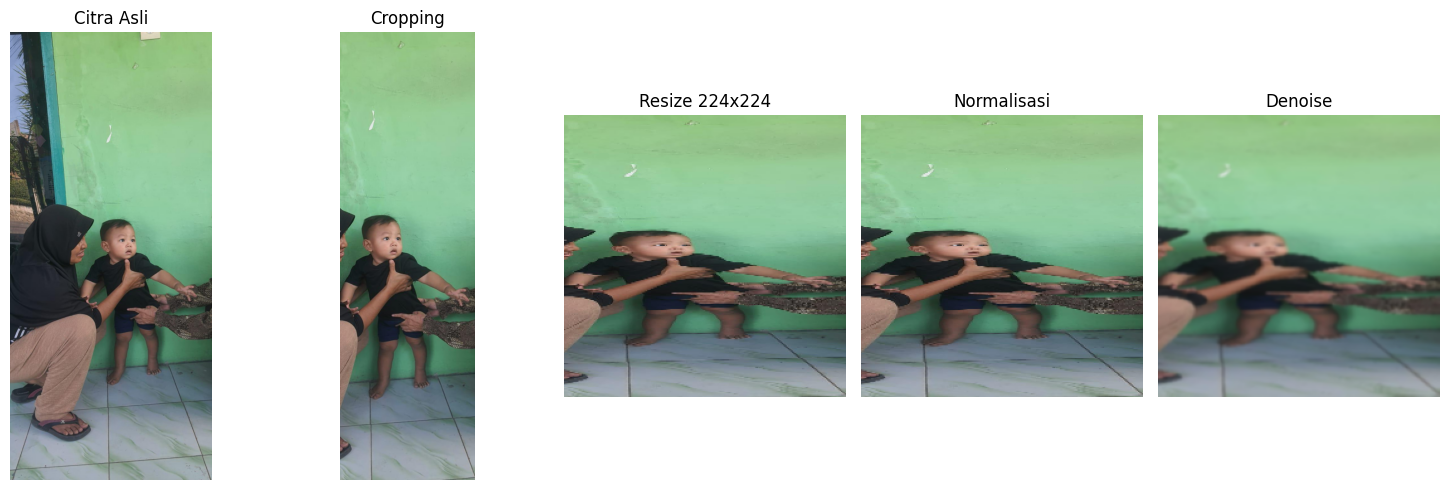


✅ Total citra berhasil diproses: 120
📁 Disimpan di folder: DATA_BALITA_PREPROCESSED


In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

# ==============================
# FOLDER
# ==============================
input_folder = "DATA_BALITA/DATA_BALITA/DATA CITRA BALITA"
output_folder = "DATA_BALITA_PREPROCESSED"

os.makedirs(output_folder, exist_ok=True)

# ==============================
# TARGET SAMPEL
# ==============================
target_sample = "79.JPG"

total = 0

# ==============================
# LOOP SEMUA GAMBAR
# ==============================
for filename in os.listdir(input_folder):
    if filename.lower().endswith((".jpg", ".jpeg", ".png")):

        img_path = os.path.join(input_folder, filename)
        img = cv2.imread(img_path)

        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        # ==============================
        # CROPPING BALITA
        # ==============================
        x1 = int(w * 0.35)
        x2 = int(w * 0.95)
        y1 = int(h * 0.05)
        y2 = int(h * 0.95)

        crop = img_rgb[y1:y2, x1:x2]

        # ==============================
        # RESIZE
        # ==============================
        resize = cv2.resize(crop, (224, 224))

        # ==============================
        # NORMALISASI
        # ==============================
        normalize = resize / 255.0

        # ==============================
        # DENOISE
        # ==============================
        denoise = cv2.GaussianBlur(resize, (5, 5), 0)

        # ==============================
        # SIMPAN HASIL
        # ==============================
        save_path = os.path.join(output_folder, filename)
        cv2.imwrite(save_path, (normalize * 255).astype("uint8"))

        total += 1

        # ==============================
        # TAMPILKAN SAMPEL 79.JPG
        # ==============================
        if filename.lower() == target_sample.lower():

            print("=== MENAMPILKAN SAMPEL: 79.JPG ===")

            print("Ukuran Citra Asli :", img.shape[:2])
            print("Ukuran Setelah Crop :", crop.shape[:2])
            print("Ukuran Setelah Resize :", resize.shape[:2])

            print("\n=== CONTOH NILAI PIXEL ===")
            print("Sebelum Normalisasi:", resize[0,0])
            print("Sesudah Normalisasi:", normalize[0,0])
            print("Setelah Noise Reduction:", denoise[0,0])

            print("\nNilai Min:", normalize.min())
            print("Nilai Max:", normalize.max())

            # ==============================
            # VISUALISASI
            # ==============================
            plt.figure(figsize=(15,5))

            plt.subplot(1,5,1)
            plt.imshow(img_rgb)
            plt.title("Citra Asli")
            plt.axis('off')

            plt.subplot(1,5,2)
            plt.imshow(crop)
            plt.title("Cropping")
            plt.axis('off')

            plt.subplot(1,5,3)
            plt.imshow(resize)
            plt.title("Resize 224x224")
            plt.axis('off')

            plt.subplot(1,5,4)
            plt.imshow(normalize)
            plt.title("Normalisasi")
            plt.axis('off')

            plt.subplot(1,5,5)
            plt.imshow(denoise)
            plt.title("Denoise")
            plt.axis('off')

            plt.tight_layout()
            plt.show()

# ==============================
# HASIL AKHIR
# ==============================
print(f"\n✅ Total citra berhasil diproses: {total}")
print(f"📁 Disimpan di folder: {output_folder}")

# **EKSTRAKSI FITUR CITRA MENGUNAKAN CNN**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,392 (75.75 KB)

 Trainable params: 19,392 (75.75 KB)

 Non-trainable params: 0 (0.00 B)


✅ Total gambar diproses : 120
📊 Panjang fitur        : 64


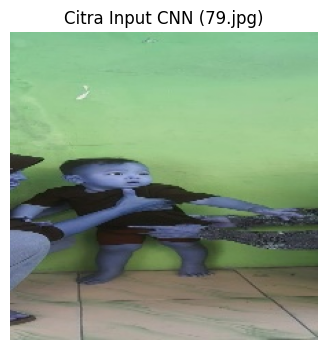

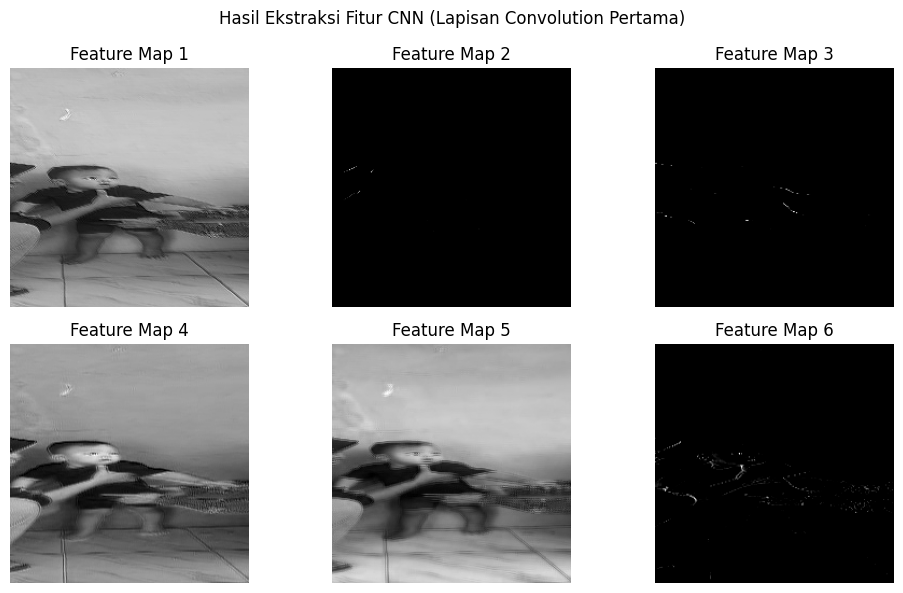


Shape Input       : (1, 224, 224, 3)
Shape Fitur CNN   : (64,)
Jumlah Fitur CNN  : 64


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Input, GlobalAveragePooling2D

# ==============================
# FOLDER DATA
# ==============================
folder = "DATA_BALITA_PREPROCESSED"

# ==============================
# MODEL CNN
# ==============================
model = Sequential([
    Input(shape=(224,224,3)),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    GlobalAveragePooling2D()
])

model.summary()

# ==============================
# PENYIMPANAN FITUR
# ==============================
features = []
filenames = []

sample_img = None
sample_input = None

# ==============================
# LOOP SEMUA GAMBAR
# ==============================
for file in os.listdir(folder):
    if file.lower().endswith(('.jpg','.jpeg','.png')):

        path = os.path.join(folder, file)

        img = cv2.imread(path)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224,224))
        img = img / 255.0

        input_img = np.expand_dims(img, axis=0)

        # EKSTRAKSI FITUR CNN
        feature = model.predict(input_img, verbose=0)

        features.append(feature.flatten())
        filenames.append(file)

        # SIMPAN SAMPLE 79.JPG
        if file.lower() == "79.jpg":
            sample_img = img
            sample_input = input_img

# ==============================
# HASIL EKSTRAKSI
# ==============================
print("\n✅ Total gambar diproses :", len(features))
print("📊 Panjang fitur        :", len(features[0]))

# ==============================
# VISUALISASI SAMPLE (79.JPG)
# ==============================
if sample_img is not None:

    # WAJIB: jalankan model dulu supaya tidak error
    _ = model.predict(sample_input, verbose=0)

    # ambil output conv layer
    layer_outputs = [layer.output for layer in model.layers if "conv" in layer.name]

    # model untuk ambil feature map
    activation_model = Model(inputs=model.inputs, outputs=layer_outputs)

    activations = activation_model.predict(sample_input, verbose=0)

    # ==============================
    # TAMPILKAN GAMBAR INPUT
    # ==============================
    plt.figure(figsize=(4,4))
    plt.imshow(sample_img)
    plt.title("Citra Input CNN (79.jpg)")
    plt.axis('off')
    plt.show()

    # ==============================
    # TAMPILKAN FEATURE MAP
    # ==============================
    first_layer = activations[0]

    plt.figure(figsize=(10,6))
    for i in range(6):
        plt.subplot(2,3,i+1)
        plt.imshow(first_layer[0,:,:,i], cmap='gray')
        plt.title(f"Feature Map {i+1}")
        plt.axis('off')

    plt.suptitle("Hasil Ekstraksi Fitur CNN (Lapisan Convolution Pertama)")
    plt.tight_layout()
    plt.show()

    # ==============================
    # INFO SHAPE
    # ==============================
    print("\nShape Input       :", sample_input.shape)
    print("Shape Fitur CNN   :", features[0].shape)
    print("Jumlah Fitur CNN  :", len(features[0]))

else:
    print("⚠️ File 79.jpg tidak ditemukan di folder!")

# **FEATURE FUSION**

In [ ]:
import pandas as pd

# 1. 7Fitur kesehatan
fitur_kesehatan = df[['BB (kg)', 'TB (cm)', 'Umur']].copy()

# Clean health feature column names
fitur_kesehatan.columns = ['BB_kg', 'TB_cm', 'Umur_Bulan']

# 2. Ambil label (target)
# 'Kategori' column from 'df' is already numerically encoded (0 or 1) by cell oqKXBenDomRr.
# No further mapping is needed here, otherwise it will result in NaNs.
label = df[['Kategori']].copy()

y = label # Keep for compatibility, though y will be reassigned later

# Convert the 'features' list (from CNN extraction) into a DataFrame named df_cnn
df_cnn = pd.DataFrame(features)

# Ensure df_cnn column names are strings and unique (e.g., 'cnn_feature_0', 'cnn_feature_1')
df_cnn.columns = [f'cnn_feature_{col}' for col in range(df_cnn.shape[1])]

# 3. Gabungkan semua fitur
df_final = pd.concat([
    fitur_kesehatan.reset_index(drop=True),
    label.reset_index(drop=True),
    df_cnn.reset_index(drop=True)
], axis=1)

# Final safeguard: ensure all column names are strings
df_final.columns = df_final.columns.astype(str)

# =====================================================
# CEK HASIL
# =====================================================
print(df_final.head())
print(df_final.shape)

pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

print("\n=== HASIL FEATURE FUSION ===")
print("Jumlah Data :", df_final.shape[0])
print("Fitur Kesehatan :", fitur_kesehatan.shape[1])
print("Fitur CNN :", df_cnn.shape[1])
print("Total Kolom :", df_final.shape[1])


# =====================================================
# SIMPAN
# =====================================================
df_final.to_excel("DATA_FUSION_FINAL.xlsx", index=False)

print("\n✅ SELESAI! File tersimpan: DATA_FUSION_FINAL.xlsx")

   BB_kg  TB_cm  Umur_Bulan  Kategori  cnn_feature_0  cnn_feature_1  \
0    5.8   65.0          24         1       0.013477       0.145110   
1    5.5   59.0          24         1       0.014330       0.076135   
2    6.7   71.5          28         1       0.013424       0.098403   
3    8.1   72.5          30         1       0.027467       0.124397   
4    6.9   73.0          28         1       0.015824       0.120207   

   cnn_feature_2  cnn_feature_3  cnn_feature_4  cnn_feature_5  ...  \
0       0.001371       0.000028       0.041761       0.033231  ...   
1       0.003551       0.000332       0.027774       0.017828  ...   
2       0.003772       0.000836       0.025569       0.030151  ...   
3       0.002828       0.000232       0.043868       0.029684  ...   
4       0.002081       0.000142       0.036467       0.027866  ...   

   cnn_feature_54  cnn_feature_55  cnn_feature_56  cnn_feature_57  \
0        0.000000        0.231663        0.197500        0.134656   
1        0.000

In [ ]:
from IPython.display import display

display(df_final)

,BB_kg,TB_cm,Umur_Bulan,Kategori,cnn_feature_0,cnn_feature_1,cnn_feature_2,cnn_feature_3,cnn_feature_4,cnn_feature_5,cnn_feature_6,cnn_feature_7,cnn_feature_8,cnn_feature_9,cnn_feature_10,cnn_feature_11,cnn_feature_12,cnn_feature_13,cnn_feature_14,cnn_feature_15,cnn_feature_16,cnn_feature_17,cnn_feature_18,cnn_feature_19,cnn_feature_20,cnn_feature_21,cnn_feature_22,cnn_feature_23,cnn_feature_24,cnn_feature_25,cnn_feature_26,cnn_feature_27,cnn_feature_28,cnn_feature_29,cnn_feature_30,cnn_feature_31,cnn_feature_32,cnn_feature_33,cnn_feature_34,cnn_feature_35,cnn_feature_36,cnn_feature_37,cnn_feature_38,cnn_feature_39,cnn_feature_40,cnn_feature_41,cnn_feature_42,cnn_feature_43,cnn_feature_44,cnn_feature_45,cnn_feature_46,cnn_feature_47,cnn_feature_48,cnn_feature_49,cnn_feature_50,cnn_feature_51,cnn_feature_52,cnn_feature_53,cnn_feature_54,cnn_feature_55,cnn_feature_56,cnn_feature_57,cnn_feature_58,cnn_feature_59,cnn_feature_60,cnn_feature_61,cnn_feature_62,cnn_feature_63
0,5.800,65.0,24,1,0.013477,0.145110,0.001371,0.000028,0.041761,0.033231,0.096983,0.013961,0.000000,0.063988,0.209771,0.000000e+00,0.000002,0.082536,0.000003,0.075621,0.000345,0.113032,0.000416,0.086791,0.000000,1.423669e-05,0.174714,1.398244e-05,0.160335,0.191014,0.103403,0.001685,0.006251,0.116141,0.000915,0.000135,0.000000,0.324603,0.000124,0.004530,0.244082,0.242502,0.000000e+00,0.122811,0.109160,0.232321,0.000157,0.000000e+00,0.000069,0.027443,0.187612,0.001463,0.000000,0.174682,0.088904,0.005837,0.000304,0.053052,0.000000,0.231663,0.197500,0.134656,0.000015,0.026837,0.025937,0.000000,0.025970,0.439139
1,5.500,59.0,24,1,0.014330,0.076135,0.003551,0.000332,0.027774,0.017828,0.047432,0.012209,0.000000,0.044585,0.115016,0.000000e+00,0.000141,0.046020,0.000183,0.039961,0.002052,0.062691,0.003011,0.048832,0.000000,1.646820e-04,0.095090,6.656670e-05,0.089100,0.097102,0.064991,0.002866,0.004157,0.059601,0.001594,0.001013,0.000000,0.176704,0.000440,0.004037,0.129964,0.128161,0.000000e+00,0.070153,0.064124,0.121870,0.000959,9.448789e-05,0.000874,0.022676,0.111517,0.003277,0.000000,0.091924,0.049079,0.004243,0.002928,0.026288,0.000000,0.106494,0.108438,0.071105,0.000220,0.013699,0.014051,0.000010,0.016410,0.240832
2,6.700,71.5,28,1,0.013424,0.098403,0.003772,0.000836,0.025569,0.030151,0.077196,0.009444,0.000124,0.037205,0.146102,8.981192e-05,0.000322,0.061307,0.000412,0.056576,0.002585,0.077687,0.002626,0.065939,0.000057,5.157698e-04,0.117889,2.648241e-04,0.111933,0.144676,0.066697,0.002897,0.014146,0.089363,0.003088,0.001379,0.000018,0.228428,0.000597,0.006263,0.175708,0.172738,1.166558e-04,0.073942,0.068128,0.165863,0.001128,5.389281e-04,0.001346,0.011975,0.126179,0.004586,0.000021,0.128598,0.069270,0.008880,0.001743,0.051912,0.000004,0.182349,0.142748,0.096714,0.000748,0.019756,0.034556,0.000105,0.024572,0.304756
3,8.100,72.5,30,1,0.027467,0.124397,0.002828,0.000232,0.043868,0.029684,0.078854,0.023710,0.000007,0.074467,0.193018,0.000000e+00,0.000070,0.069559,0.000031,0.066880,0.001010,0.099541,0.001559,0.086812,0.000000,6.733805e-05,0.160651,2.831665e-05,0.149262,0.161984,0.106359,0.001922,0.009400,0.098778,0.001234,0.000997,0.000000,0.284332,0.000394,0.006885,0.213155,0.206933,1.832185e-05,0.115970,0.102078,0.198203,0.000584,3.525618e-04,0.000689,0.036209,0.179196,0.003655,0.000000,0.150338,0.085367,0.010001,0.000652,0.047908,0.000000,0.178872,0.177538,0.116770,0.000241,0.031553,0.018233,0.000000,0.028353,0.384465
4,6.900,73.0,28,1,0.015824,0.120207,0.002081,0.000142,0.036467,0.027866,0.081863,0.014041,0.000004,0.059198,0.182224,1.000491e-07,0.000027,0.067417,0.000015,0.064316,0.001017,0.096117,0.002704,0.074827,0.000000,3.940349e-05,0.149855,5.066906e-07,0.134779,0.163270,0.091240,0.001900,0.006910,0.099498,0.000899,0.000281,0.000000,0.276854,0.000185,0.004929,0.205274,0.208237,0.000000e+00,0.102913,0.091963,0.196570,0.000745,6.854205e-07,0.001032,0.024988,0.164059,0.002135,0.000000,0.150694,0.079167,0.005072,0.003298,0.045424,0.000000,0.193983,0.169767,0.111222,0

# **PEMBAGIAN DATASET**

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np # Import numpy for NaN handling

# =====================================================
# TARGET (LABEL)
# =====================================================
# Reload df from the original excel to ensure 'Kategori' is correctly processed for y
# This makes the y definition independent of potential global df inconsistencies
excel_path = '/content/DATA_BALITA/DATA_BALITA/DATASET_FINAL.xlsx'
df_temp = pd.read_excel(excel_path)

# Ensure 'Umur' column is numerical before any further processing (if needed for consistency)
if 'Umur' in df_temp.columns:
    df_temp['Umur'] = df_temp['Umur'].astype(str).str.replace(' Bulan', '', regex=False).replace('', np.nan).astype(float)

# Re-apply 'Kategori' mapping to ensure it's numerical (0/1)
if 'Kategori' in df_temp.columns:
    df_temp['Kategori'] = df_temp['Kategori'].astype(str).str.strip().str.lower()
    df_temp['Kategori'] = df_temp['Kategori'].map({
        'tidak stunting': 0,
        'stunting': 1
    })

X = df_final.drop('Kategori', axis=1)
y = df_final['Kategori']

print("\n--- Verifikasi y (Kategori) ---")
print("y null count:", y.isnull().sum())
print("y unique values:\n", y.value_counts())


# =====================================================
# FITUR
# =====================================================
X = df_final.drop('Kategori', axis=1)
y = df_final['Kategori']

# Handle NaN values in y by removing corresponding rows from X and y
# With the above explicit processing for y, 'Kategori' should no longer have NaNs, so this mask will be all True.
non_nan_mask = y.notna()
X_filtered = X[non_nan_mask]
y_filtered = y[non_nan_mask]

# =====================================================
# SPLIT DATA (80:20)
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y_filtered,
    test_size=0.2,
    random_state=42,
    stratify=y_filtered
)

# =====================================================
# HASIL
# =====================================================
print("\n=== PEMBAGIAN DATASET ===")
print("Total Data :", len(X_filtered))
print("Train :", len(X_train))
print("Test :", len(X_test))

print("\nDistribusi Train:")
print(y_train.value_counts())

print("\nDistribusi Test:")
print(y_test.value_counts())


--- Verifikasi y (Kategori) ---
y null count: 0
y unique values:
 Kategori
1    63
0    57
Name: count, dtype: int64

=== PEMBAGIAN DATASET ===
Total Data : 120
Train : 96
Test : 24

Distribusi Train:
Kategori
1    50
0    46
Name: count, dtype: int64

Distribusi Test:
Kategori
1    13
0    11
Name: count, dtype: int64


# **HYPERPARAMETER TUNING DAN TRAINING**

Best SVM Params: {'C': 0.1, 'gamma': 0.001}
Best CV Accuracy: 0.6773684210526316


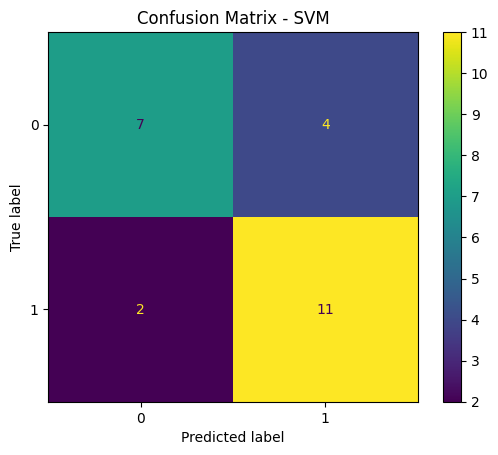

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np # Added for np.nan


# PARAMETER SVM
param_svm = {
    'C': [0.01, 0.05, 0.1],
    'gamma': [0.001, 0.01]
}
# GRID SEARCH
grid_svm = GridSearchCV(
    estimator=SVC(),
    param_grid=param_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Use processed data for fitting
grid_svm.fit(X_train, y_train)

best_svm = grid_svm.best_estimator_

print("Best SVM Params:", grid_svm.best_params_)
print("Best CV Accuracy:", grid_svm.best_score_)

# PREDIKSI
y_pred_svm = best_svm.predict(X_test) # Use processed data for prediction

# CONFUSION MATRIX VISUAL
cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm)
disp.plot()
plt.title("Confusion Matrix - SVM")
plt.show()

In [ ]:
print("Best Params:", grid_svm.best_params_)
print("Best CV:", grid_svm.best_score_)
print("Train:", best_svm.score(X_train, y_train))
print("Test :", best_svm.score(X_test, y_test))

Best Params: {'C': 0.1, 'gamma': 0.001}
Best CV: 0.6773684210526316
Train: 0.7916666666666666
Test : 0.75


Best RF Params: {'max_depth': 3, 'min_samples_leaf': 8, 'min_samples_split': 20, 'n_estimators': 50}
Best CV Accuracy: 0.7610526315789474


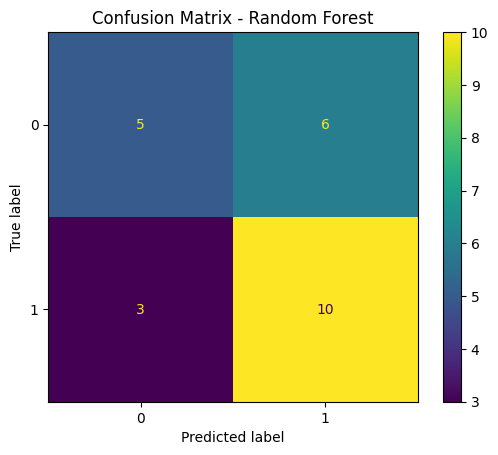

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# PARAMETER RF
param_rf = {
    'n_estimators': [50, 100],
    'max_depth': [2, 3],
    'min_samples_split': [20, 30, 40],
    'min_samples_leaf': [4, 6, 8]
}

# GRID SEARCH
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(42),
    param_grid=param_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Use processed data for fitting
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_

print("Best RF Params:", grid_rf.best_params_)
print("Best CV Accuracy:", grid_rf.best_score_)

# PREDIKSI
y_pred_rf = best_rf.predict(X_test) # Use processed data for prediction

# CONFUSION MATRIX VISUAL
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [ ]:
print("Best RF Params:", grid_rf.best_params_)
print("Best CV:", grid_rf.best_score_)
print("Train:", best_rf.score(X_train, y_train))
print("Test :", best_rf.score(X_test, y_test))

Best RF Params: {'max_depth': 3, 'min_samples_leaf': 8, 'min_samples_split': 20, 'n_estimators': 50}
Best CV: 0.7610526315789474
Train: 0.8854166666666666
Test : 0.625


# **KLASIFIKASI ENSAMBLE LEARNING VOTING**

=== HARD VOTING CLASSIFIER ===
Accuracy: 0.75


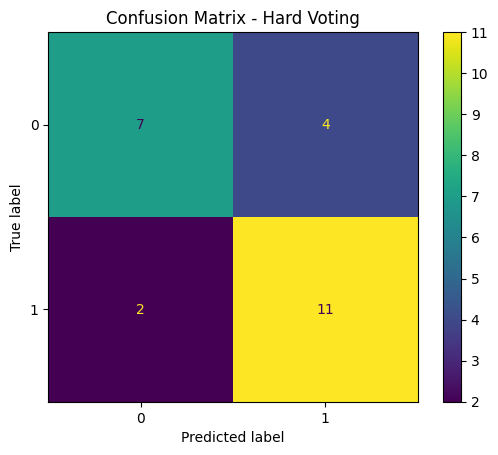

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.svm import SVC
import matplotlib.pyplot as plt

# ======================================
# FIX SVM AGAR SUPPORT VOTING
# ======================================
best_svm_soft = SVC(
    C=grid_svm.best_params_['C'],
    gamma=grid_svm.best_params_['gamma'],
    kernel='rbf',
    probability=True
)

best_svm_soft.fit(X_train, y_train)

# ======================================
# VOTING CLASSIFIER
# ======================================
voting_model = VotingClassifier(
    estimators=[
        ('svm', best_svm_soft),
        ('rf', best_rf)
    ],
    voting='hard',
    weights=[2, 1]
)

# TRAINING
voting_model.fit(X_train, y_train)

# PREDIKSI
y_pred_vote = voting_model.predict(X_test)

# ======================================
# EVALUASI
# ======================================
print("=== HARD VOTING CLASSIFIER ===")
print("Accuracy:", accuracy_score(y_test, y_pred_vote))

# ======================================
# CONFUSION MATRIX
# ======================================
cm_vote = confusion_matrix(y_test, y_pred_vote)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_vote)
disp.plot()
plt.title("Confusion Matrix - Hard Voting")
plt.show()

In [ ]:
train_acc = voting_model.score(X_train, y_train)
test_acc = voting_model.score(X_test, y_test)
print(f"Training Accuracy : {train_acc*100:.2f}%")
print(f"Testing Accuracy  : {test_acc*100:.2f}%")

Training Accuracy : 79.17%
Testing Accuracy  : 75.00%


# **PERBANDINGAN MODEL KLASIFIKASI**

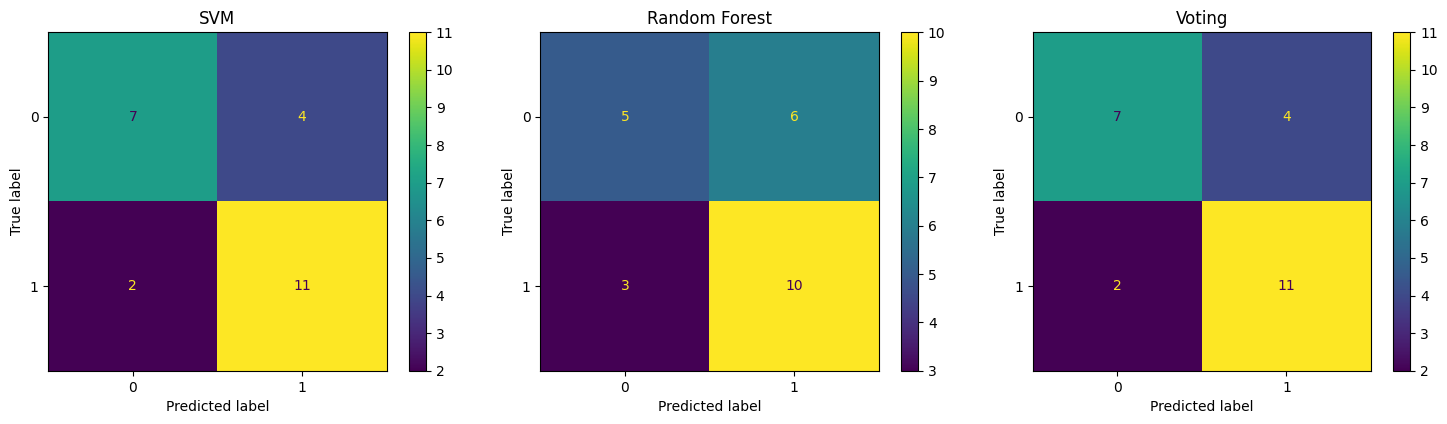

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf,
    "Voting": y_pred_vote
}

plt.figure(figsize=(15, 4))

for i, (name, y_pred) in enumerate(models.items()):
    plt.subplot(1, 3, i+1)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=plt.gca())
    plt.title(name)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# ==============================
# HITUNG METRIK
# ==============================
results = {
    "Model": [],
    "Accuracy": [],
    "Precision": [],
    "Recall": [],
    "F1-Score": []
}

# ==============================
# SVM
# ==============================
results["Model"].append("SVM")
results["Accuracy"].append(accuracy_score(y_test, y_pred_svm))
results["Precision"].append(precision_score(y_test, y_pred_svm, zero_division=0))
results["Recall"].append(recall_score(y_test, y_pred_svm, zero_division=0))
results["F1-Score"].append(f1_score(y_test, y_pred_svm, zero_division=0))

# ==============================
# RANDOM FOREST
# ==============================
results["Model"].append("Random Forest")
results["Accuracy"].append(accuracy_score(y_test, y_pred_rf))
results["Precision"].append(precision_score(y_test, y_pred_rf, zero_division=0))
results["Recall"].append(recall_score(y_test, y_pred_rf, zero_division=0))
results["F1-Score"].append(f1_score(y_test, y_pred_rf, zero_division=0))

# ==============================
# VOTING CLASSIFIER
# ==============================
results["Model"].append("Voting Classifier")
results["Accuracy"].append(accuracy_score(y_test, y_pred_vote))
results["Precision"].append(precision_score(y_test, y_pred_vote, zero_division=0))
results["Recall"].append(recall_score(y_test, y_pred_vote, zero_division=0))
results["F1-Score"].append(f1_score(y_test, y_pred_vote, zero_division=0))

# ==============================
# DATAFRAME
# ==============================
df_results = pd.DataFrame(results)

# Bulatkan biar rapi
df_results.iloc[:, 1:] = df_results.iloc[:, 1:].round(4)

# Urutkan berdasarkan akurasi tertinggi
df_results = df_results.sort_values(by="Accuracy", ascending=False)

print(df_results)

               Model  Accuracy  Precision  Recall  F1-Score
0                SVM     0.750     0.7333  0.8462    0.7857
2  Voting Classifier     0.750     0.7333  0.8462    0.7857
1      Random Forest     0.625     0.6250  0.7692    0.6897


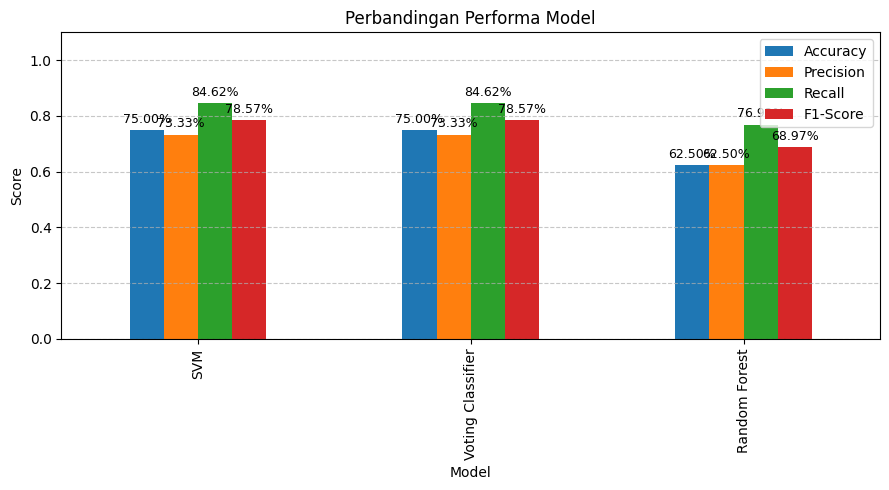

In [ ]:
import matplotlib.pyplot as plt

# Plot
ax = df_results.set_index("Model").plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Perbandingan Performa Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.1)  # beri ruang untuk label
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Tambahkan label persentase pada setiap bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt=lambda x: f'{x*100:.2f}%',
        padding=3,
        fontsize=9
    )

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()